In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# Base URL structure for pagination on Books to Scrape
base_url = "https://books.toscrape.com/catalogue/page-{}.html"

# List to store scraped book dictionaries
books_data = []

# Target: at least 200 books (20 books per page -> 10 pages = 200 books)
total_pages_to_scrape = 10

print("Starting the web scraping process...")

for page in range(1, total_pages_to_scrape + 1):
    url = base_url.format(page)
    response = requests.get(url)
    
    # Check if the page loaded successfully
    if response.status_code != 200:
        print(f"Failed to retrieve page {page}. Status code: {response.status_code}")
        continue
        
    soup = BeautifulSoup(response.text, 'html.parser')
    
    # Find all product containers on the page
    products = soup.find_all('article', class_='product_pod')
    
    for product in products:
        # 1. Extract Book Title
        title = product.find('h3').find('a')['title']
        
        # 2. Extract Price (in GBP)
        price_str = product.find('p', class_='price_color').text
        # Clean string to get numeric value later, or keep raw string for now
        
        # 3. Extract Star Rating (e.g., ['star-rating', 'Three'] -> 'Three')
        rating_classes = product.find('p', class_='star-rating')['class']
        star_rating = rating_classes[1] if len(rating_classes) > 1 else "Unknown"
        
        # 4. Extract Stock Availability
        availability = product.find('p', class_='instock availability').text.strip()
        
        # Append dictionary to list
        books_data.append({
            'Title': title,
            'Price_GBP': price_str,
            'Star_Rating': star_rating,
            'Availability': availability
        })

    print(f"Successfully scraped page {page}...")

# Convert collected data into a pandas DataFrame
df = pd.DataFrame(books_data)

# Preview the first 5 rows
print("\nFirst 5 rows of raw scraped data:")
print(df.head())

# Save the dataset to a CSV file for Step 2
df.to_csv('raw_books_data.csv', index=False)
print("\nScraping complete! Data saved to 'raw_books_data.csv'.")

Starting the web scraping process...
Successfully scraped page 1...
Successfully scraped page 2...
Successfully scraped page 3...
Successfully scraped page 4...
Successfully scraped page 5...
Successfully scraped page 6...
Successfully scraped page 7...
Successfully scraped page 8...
Successfully scraped page 9...
Successfully scraped page 10...

First 5 rows of raw scraped data:
                                   Title Price_GBP Star_Rating Availability
0                   A Light in the Attic   Â£51.77       Three     In stock
1                     Tipping the Velvet   Â£53.74         One     In stock
2                             Soumission   Â£50.10         One     In stock
3                          Sharp Objects   Â£47.82        Four     In stock
4  Sapiens: A Brief History of Humankind   Â£54.23        Five     In stock

Scraping complete! Data saved to 'raw_books_data.csv'.


In [5]:
import pandas as pd
import numpy as np

# 1. Load the raw scraped data
df = pd.read_csv('raw_books_data.csv')

print("--- Initial Data Preview ---")
print(df.head())
print(f"\nInitial row count: {len(df)}")

# 2. Clean the Price Column
# The raw price typically looks like '£51.77' or has encoding artifacts. 
# We remove non-numeric characters (except the decimal point) and convert to float.
df['Price_GBP'] = df['Price_GBP'].astype(str).str.replace(r'[^\d.]', '', regex=True)
df['Price_GBP'] = pd.to_numeric(df['Price_GBP'], errors='coerce')

# 3. Clean the Star Rating Column
# Maps text ratings ("One" to "Five") to integers (1 to 5) for modeling
rating_mapping = {
    'One': 1,
    'Two': 2,
    'Three': 3,
    'Four': 4,
    'Five': 5
}
df['Star_Rating_Num'] = df['Star_Rating'].map(rating_mapping)

# 4. Clean the Availability Column
# Extracting a binary indicator: 1 if 'In stock', 0 otherwise
df['In_Stock'] = df['Availability'].str.contains('In stock', case=False, na=False).astype(int)

# 5. Handle Missing or Inconsistent Entries
# Check for null values and drop or impute them appropriately
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Drop rows where essential modelling columns (Price or Rating) are missing
df = df.dropna(subset=['Price_GBP', 'Star_Rating_Num'])

# Remove duplicate books if any were scraped twice
df = df.drop_duplicates(subset=['Title'])

# Reset index after cleaning
df = df.reset_index(drop=True)

print(f"\nRow count after cleaning: {len(df)}")
print("\n--- Cleaned Data Preview ---")
print(df.head())

# Save the cleaned dataset for Step 3 and Step 4
df.to_csv('cleaned_books_data.csv', index=False)
print("\nData cleaning complete! Saved to 'cleaned_books_data.csv'.")

--- Initial Data Preview ---
                                   Title Price_GBP Star_Rating Availability
0                   A Light in the Attic   Â£51.77       Three     In stock
1                     Tipping the Velvet   Â£53.74         One     In stock
2                             Soumission   Â£50.10         One     In stock
3                          Sharp Objects   Â£47.82        Four     In stock
4  Sapiens: A Brief History of Humankind   Â£54.23        Five     In stock

Initial row count: 200

Missing values before cleaning:
Title              0
Price_GBP          0
Star_Rating        0
Availability       0
Star_Rating_Num    0
In_Stock           0
dtype: int64

Row count after cleaning: 200

--- Cleaned Data Preview ---
                                   Title  Price_GBP Star_Rating Availability  \
0                   A Light in the Attic      51.77       Three     In stock   
1                     Tipping the Velvet      53.74         One     In stock   
2                 

Generating visualisations...


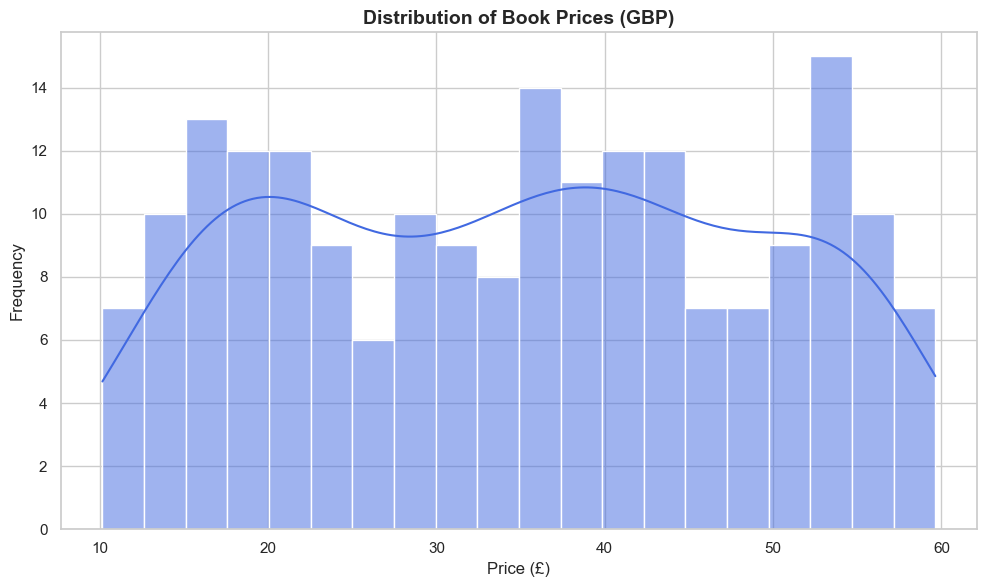

C:\Users\ThegoPheahaMalema\AppData\Local\Temp\ipykernel_24508\512748266.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Star_Rating_Num', y='Price_GBP', data=df, palette='Set2')


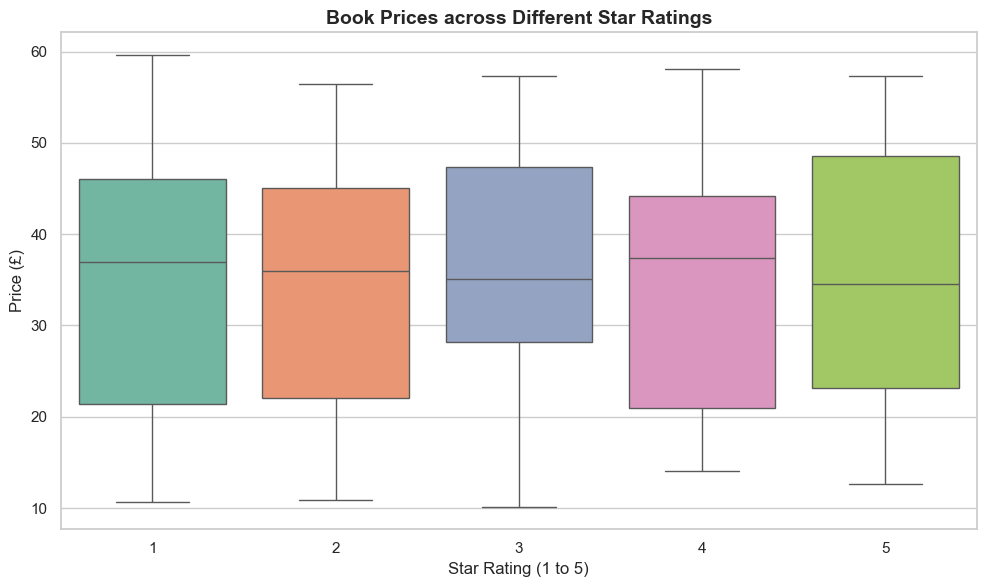

C:\Users\ThegoPheahaMalema\AppData\Local\Temp\ipykernel_24508\512748266.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Star_Rating_Num', y='Price_GBP', data=avg_price_rating, palette='viridis')


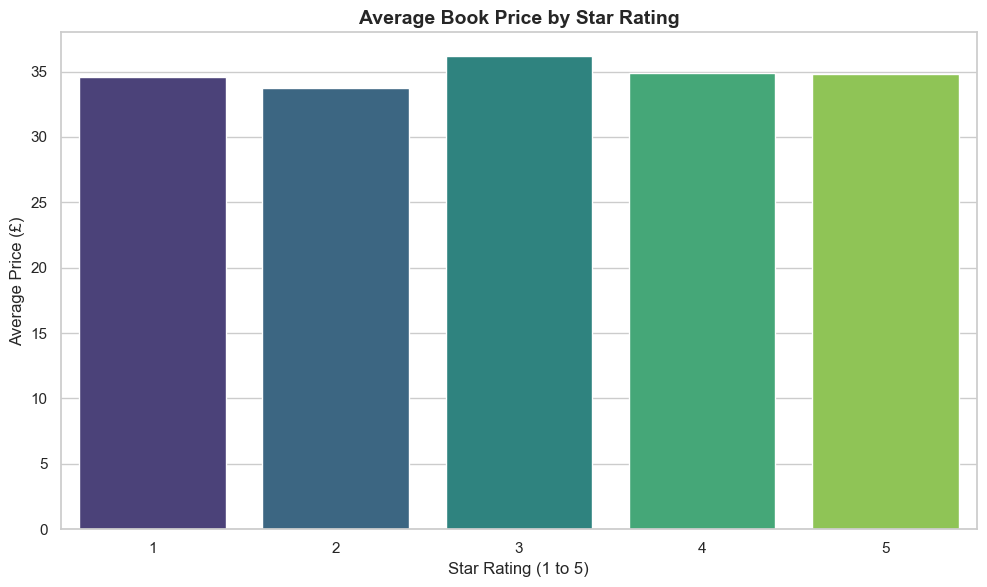

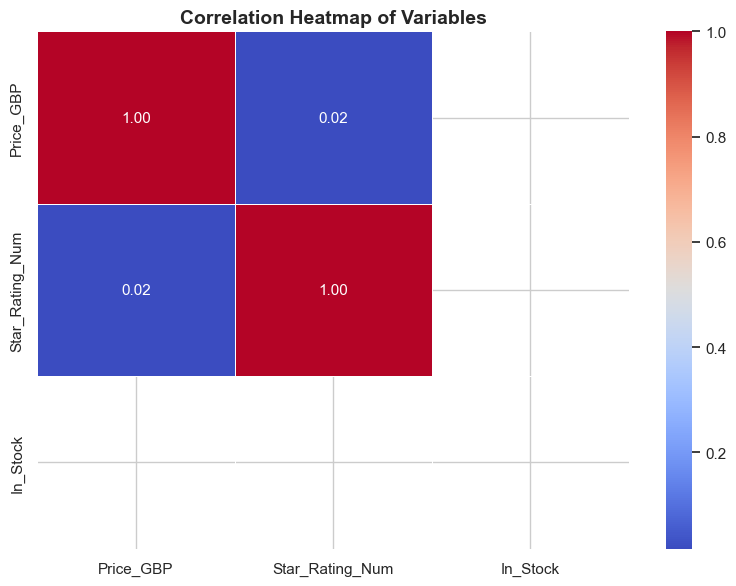

All visualisations generated and saved successfully!


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11})

# 1. Load the cleaned dataset
df = pd.read_csv('cleaned_books_data.csv')

print("Generating visualisations...")

# --- Figure 1: Distribution of Book Prices ---
plt.figure(figsize=(10, 6))
sns.histplot(df['Price_GBP'], kde=True, color='royalblue', bins=20)
plt.title('Distribution of Book Prices (GBP)', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.savefig('price_distribution.png', dpi=300)
plt.show()

# --- Figure 2: Price vs. Star Rating (Box Plot) ---
plt.figure(figsize=(10, 6))
sns.boxplot(x='Star_Rating_Num', y='Price_GBP', data=df, palette='Set2')
plt.title('Book Prices across Different Star Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Star Rating (1 to 5)', fontsize=12)
plt.ylabel('Price (£)', fontsize=12)
plt.tight_layout()
plt.savefig('price_vs_rating.png', dpi=300)
plt.show()

# --- Figure 3: Average Price per Star Rating (Bar Plot) ---
plt.figure(figsize=(10, 6))
avg_price_rating = df.groupby('Star_Rating_Num')['Price_GBP'].mean().reset_index()
sns.barplot(x='Star_Rating_Num', y='Price_GBP', data=avg_price_rating, palette='viridis')
plt.title('Average Book Price by Star Rating', fontsize=14, fontweight='bold')
plt.xlabel('Star Rating (1 to 5)', fontsize=12)
plt.ylabel('Average Price (£)', fontsize=12)
plt.tight_layout()
plt.savefig('avg_price_by_rating.png', dpi=300)
plt.show()

# --- Figure 4: Correlation Heatmap of Numerical Features ---
plt.figure(figsize=(8, 6))
# Selecting numerical columns for correlation
numeric_cols = df[['Price_GBP', 'Star_Rating_Num', 'In_Stock']]
corr = numeric_cols.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

print("All visualisations generated and saved successfully!")

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load the cleaned dataset
df = pd.read_csv('cleaned_books_data.csv')

print("--- Preparing Dataset for Modelling ---")

# Feature Engineering: Let's create a title length feature to give the model more predictive signal
df['Title_Length'] = df['Title'].astype(str).str.len()

# Define features (X) and target variable (y)
# We will use Star Rating, Stock status, and Title Length to predict Price
features = ['Star_Rating_Num', 'In_Stock', 'Title_Length']
X = df[features]
y = df['Price_GBP']

# 2. Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# 3. Initialize and Train the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predict on the Test Set
y_pred = model.predict(X_test)

# 5. Evaluate the Model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Evaluation Metrics ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

# 6. Interpret Coefficients
print("\n--- Model Coefficients & Feature Importance ---")
for feature, coef in zip(features, model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

--- Preparing Dataset for Modelling ---
Training set shape: (160, 3)
Testing set shape: (40, 3)

--- Model Evaluation Metrics ---
Mean Squared Error (MSE): 230.6571
Root Mean Squared Error (RMSE): £15.1874
R-squared (R²): 0.0005

--- Model Coefficients & Feature Importance ---
Star_Rating_Num: 0.3212
In_Stock: 0.0000
Title_Length: 0.0391
Intercept: 31.8531
